# Project 26: Evaluasi ekstraksi spec dari PDF

Q1 akurasi per field, Q2 jenis kesalahan, Q3 aturan dasar vs aturan lengkap (LLM belum dijalankan: tidak ada kunci API di lingkungan ini), Q12 dokumen yang perlu review. Gold set: 160 field dari 24 PDF simulasi. Semua tabel dibaca dari `results/`.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'results').exists():
    ROOT = ROOT.parent
R = lambda f: pd.read_csv(next((ROOT / 'results' / d / f) for d in ('1-data-preparation', '2-analysis', '3-presentation') if (ROOT / 'results' / d / f).exists()))
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GREY, ORANGE = '#1A73E8', '#9AA0A6', '#E8710A'

## Q1. Akurasi per field dan format dokumen

In [2]:
a = R('extraction_accuracy.csv'); a.pivot_table(index=['scope', 'group'], columns='method', values='accuracy')

method                                 rule_basic  rule_full
scope          group                                        
Dokumen        semua field gold benar      0.3913     1.0000
Format dokumen ringkas                     0.2500     1.0000
               tabel                       1.0000     1.0000
               teks                        0.0000     1.0000
               terpotong                   0.4000     1.0000
Jenis field    max                         0.5172     1.0000
               min                         0.3944     1.0000
               unit                        0.5333     1.0000
Parameter      cct                         0.5000     1.0000
               cri                         0.4444     1.0000
               efficacy                    0.5455     1.0000
               luminous_flux               0.4615     1.0000
               power                       0.5000     1.0000
               power_factor                0.2941     1.0000
Semua field    semua                       0.4688     1.0000
Tingkat        batas (min dan max)         0.4300     1.0000
               parameter terbaca           0.4595     1.0000
               satuan                      0.5333     1.0000

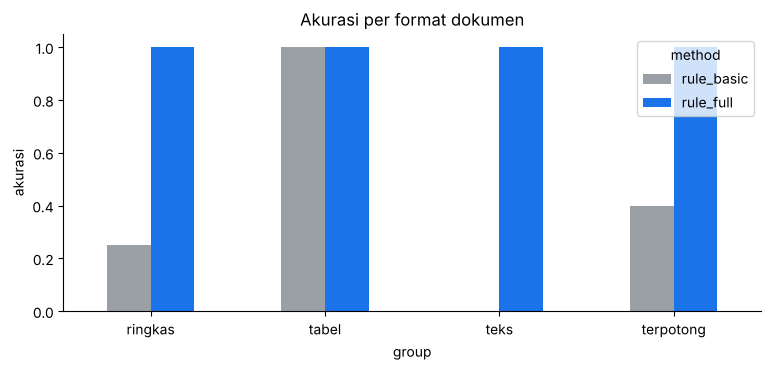

In [3]:
f = a[a.scope == 'Format dokumen'].pivot(index='group', columns='method', values='accuracy')
f.plot.bar(color=[GREY, BLUE], rot=0); plt.ylabel('akurasi'); plt.title('Akurasi per format dokumen'); plt.show()

## Q2. Kesalahan paling sering (aturan dasar)

In [4]:
e = R('extraction_errors.csv'); e

,method,error_type,n,share,cum_share
0,rule_basic,Format kalimat (bukan tabel),58,0.6824,0.6824
1,rule_basic,Label singkatan tidak dikenal,15,0.1765,0.8588
2,rule_basic,Tabel terpotong ke halaman berikutnya,12,0.1412,1.0000


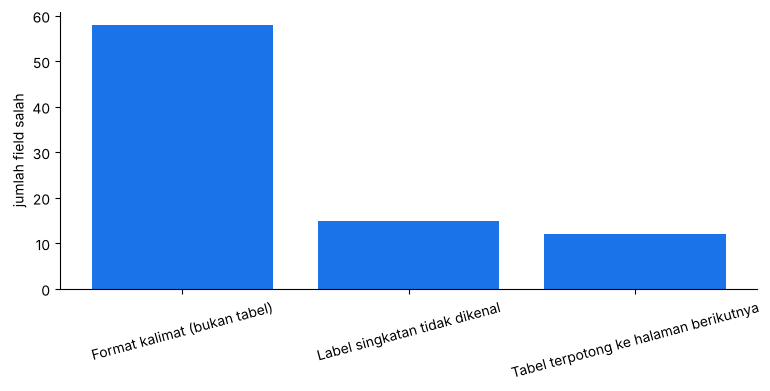

In [5]:
plt.bar(e.error_type, e.n, color=BLUE); plt.xticks(rotation=15); plt.ylabel('jumlah field salah'); plt.show()

## Q3. Aturan dasar vs aturan lengkap
Keduanya memakai pdfplumber dan regex; aturan lengkap menambah pembacaan kalimat, label singkatan, dan tabel yang terpotong. Langkah LLM (`extract/llm.py`) tersedia tetapi belum dijalankan.

In [6]:
R('extraction_doc_eval.csv').groupby('method').agg(dokumen=('doc', 'count'), lolos_skema=('schema_ok', 'sum'), cocok_kunci=('exact_vs_truth', 'sum'))

,dokumen,lolos_skema,cocok_kunci
method,,,
rule_basic,24,9,9
rule_full,24,23,23


## Q12. Dokumen yang perlu review manusia

In [7]:
display(R('review_queue.csv')); R('doc_validation.csv').groupby('method').agg(dokumen=('doc', 'count'), perlu_review=('schema_ok', lambda s: (~s).sum()))

,doc,model,revision,format,reason
0,LED_9W_Rev2.0_teks_scan.pdf,9W,Rev 2.0,teks,"tanpa lapisan teks (hasil scan), tanpa OCR"


,dokumen,perlu_review
method,,
rule_basic,24,15
rule_full,24,1


## Hasil akhir: tabel dim_spec

In [8]:
display(R('dim_spec.csv').head(18)); print(len(R('dim_spec.csv')), 'baris;', len(R('spec_conflicts.csv')), 'konflik antar format')

,model,revision,valid_from,parameter,lower_limit,upper_limit,unit,source_doc,source_page,n_docs_agree,n_docs
0,12W,Rev 1.0,2026-03-01,cct,6000.0000,7000.0000,K,LED_12W_Rev1.0_tabel.pdf,1,2,2
1,12W,Rev 1.0,2026-03-01,cri,80.0000,NaN,Ra,LED_12W_Rev1.0_tabel.pdf,1,2,2
2,12W,Rev 1.0,2026-03-01,efficacy,90.0000,NaN,lm/W,LED_12W_Rev1.0_tabel.pdf,1,2,2
3,12W,Rev 1.0,2026-03-01,luminous_flux,1100.0000,NaN,lm,LED_12W_Rev1.0_tabel.pdf,1,2,2
4,12W,Rev 1.0,2026-03-01,power,NaN,12.5000,W,LED_12W_Rev1.0_tabel.pdf,1,2,2
5,12W,Rev 1.0,2026-03-01,power_factor,0.9000,NaN,NaN,LED_12W_Rev1.0_tabel.pdf,1,2,2
6,12W,Rev 2.0,2026-05-01,cct,6000.0000,7000.0000,K,LED_12W_Rev2.0_tabel.pdf,1,3,3
7,12W,Rev 2.0,2026-05-01,cri,80.0000,NaN,Ra,LED_12W_Rev2.0_tabel.pdf,1,3,3
8,12W,Rev 2.0,2026-05-01,efficacy,90.0000,NaN,lm/W,LED_12W_Rev2.0_tabel.pdf,1,3,3
9,12W,Rev 2.0,2026-05-01,luminous_flux,1100.0000,NaN,lm,LED_12W_Rev2.0_tabel.pdf,1,3,3


54 baris; 0 konflik antar format
